# Lab 3: Khảo sát thuật toán k-Nearest Neighbors (IBk) trên bộ dữ liệu Glass

### 1. Giới thiệu bài toán và thuật toán IBk
- **IBk (Instance-Based learning with k parameter)**: Đây là cách triển khai thuật toán **k-Nearest Neighbors (k-NN)** trong Weka (`weka.classifiers.lazy.IBk`).
- **Nguyên lý hoạt động**:
  - Không xây dựng mô hình tường minh trong giai đoạn huấn luyện (*lazy learning*).
  - Khi cần phân lớp cho mẫu mới, thuật toán tính khoảng cách (mặc định là khoảng cách Euclidean chuẩn hóa) từ mẫu mới tới toàn bộ các điểm trong tập huấn luyện.
  - Chọn ra $k$ điểm láng giềng gần nhất và cho các láng giềng này "bỏ phiếu" (majority vote) để quyết định nhãn lớp cho mẫu cần dự đoán.
- **Mục tiêu thực nghiệm**:
  1. Đọc và khám phá dữ liệu `datasets/glass.arff` (214 mẫu, 9 thuộc tính hóa học, 6 loại kính).
  2. Chạy thuật toán IBk với các giá trị $k$ biến thiên từ $1$ đến $35$.
  3. Khảo sát độ chính xác (**Accuracy**) theo cả 2 chế độ:
     - **10-fold Cross-Validation** (kiểm định chéo 10 phần - chế độ mặc định trong Weka).
     - **Training Set** (đo lường trực tiếp trên dữ liệu huấn luyện để quan sát hiện tượng Overfitting).
  4. Vẽ đồ thị phân phối trực quan với trục $X$ là các giá trị $k$ và trục $Y$ là độ chính xác (Accuracy %).
  5. Đánh giá chi tiết các mốc $k = 1, 5, 20$ theo yêu cầu của bài Lab 3 (Lab3-Form).


In [1]:
import os
import re
import warnings
import subprocess
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import arff
from sklearn.preprocessing import MinMaxScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score

warnings.filterwarnings('ignore')

# Cấu hình thẩm mỹ cho biểu đồ matplotlib
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3
plt.rcParams['grid.linestyle'] = '--'

DATASET_PATH = Path("datasets/glass.arff")
print(f"Đường dẫn dataset: {DATASET_PATH.resolve()}")
print(f"Dataset tồn tại: {DATASET_PATH.exists()}")


Đường dẫn dataset: E:\lab-data-mining\datasets\glass.arff
Dataset tồn tại: True


## 2. Khám phá tập dữ liệu `glass.arff`

Bộ dữ liệu `glass` mô tả 214 mẫu mảnh kính thu thập tại hiện trường vụ án, được phân tích quang học và thành phần hóa học để phân loại mục đích sử dụng.
- **Số mẫu**: 214
- **Số thuộc tính đặc trưng**: 9 thuộc tính số thực (RI: Chỉ số khúc xạ, Na, Mg, Al, Si, K, Ca, Ba, Fe: Nồng độ các oxit khoáng chất).
- **Thuộc tính nhãn (Class)**: `Type` gồm 6 phân lớp khác nhau.


In [2]:
# Đọc file ARFF
data, meta = arff.loadarff(DATASET_PATH)
df = pd.DataFrame(data)

# Giải mã nhãn lớp từ bytes sang string
df['Type'] = df['Type'].str.decode('utf-8')

print(f"Kích thước tập dữ liệu: {df.shape[0]} dòng, {df.shape[1]} cột")
print("\n5 dòng đầu tiên:")
display(df.head())

print("\nPhân phối các lớp kính (Type):")
dem_lop = df['Type'].value_counts()
ti_le_lop = df['Type'].value_counts(normalize=True) * 100
thong_ke_lop = pd.DataFrame({'Số lượng mẫu': dem_lop, 'Tỷ lệ (%)': ti_le_lop.round(2)})
display(thong_ke_lop)

# Baseline ZeroR (đoán theo lớp đa số nhất: 'build wind non-float')
lop_da_so = dem_lop.index[0]
acc_zeror = ti_le_lop.iloc[0]
print(f"-> Baseline ZeroR (đoán luôn '{lop_da_so}'): {acc_zeror:.2f}% ({dem_lop.iloc[0]}/{len(df)} mẫu đúng)")


Kích thước tập dữ liệu: 214 dòng, 10 cột

5 dòng đầu tiên:


,RI,Na,Mg,Al,Si,'K',Ca,Ba,Fe,Type
0,1.51793,12.79,3.50,1.12,73.03,0.64,8.77,0.0,0.00,build wind float
1,1.51643,12.16,3.52,1.35,72.89,0.57,8.53,0.0,0.00,vehic wind float
2,1.51793,13.21,3.48,1.41,72.64,0.59,8.43,0.0,0.00,build wind float
3,1.51299,14.40,1.74,1.54,74.55,0.00,7.59,0.0,0.00,tableware
4,1.53393,12.30,0.00,1.00,70.16,0.12,16.19,0.0,0.24,build wind non-float



Phân phối các lớp kính (Type):


,Số lượng mẫu,Tỷ lệ (%)
Type,,
build wind non-float,76,35.51
build wind float,70,32.71
headlamps,29,13.55
vehic wind float,17,7.94
containers,13,6.07
tableware,9,4.21


-> Baseline ZeroR (đoán luôn 'build wind non-float'): 35.51% (76/214 mẫu đúng)


## 3. Khảo sát thuật toán IBk (Weka CLI) với dải giá trị $k$ từ 1 đến 35

Ta tiến hành chạy thuật toán `weka.classifiers.lazy.IBk` từ Weka 3.9 bằng Java CLI trên file `datasets/glass.arff`. Với mỗi giá trị $k$, ta thu thập:
1. **Độ chính xác trên Training Set** (đo lường khả năng ghi nhớ và mức độ overfitting).
2. **Độ chính xác qua 10-fold Stratified Cross-Validation** (đo lường độ chính xác tổng quát hóa khi gặp dữ liệu chưa biết).


In [3]:
def tim_weka_jar():
    """Tìm đường dẫn file weka.jar trên hệ thống."""
    cac_duong_dan = [
        Path("C:/Program Files/Weka-3-9-6/weka.jar"),
        Path("C:/Program Files/Weka-3-8-6/weka.jar"),
        Path("C:/Program Files (x86)/Weka-3-9-6/weka.jar"),
        Path("C:/Program Files (x86)/Weka-3-8-6/weka.jar"),
    ]
    for p in cac_duong_dan:
        if p.exists():
            return str(p)
    return "weka.jar"

WEKA_JAR = tim_weka_jar()
print(f"Sử dụng Weka jar tại: {WEKA_JAR}")

def chay_weka_ibk(k, dataset_path=DATASET_PATH):
    """Chạy Weka IBk cho giá trị k cụ thể và bóc tách kết quả."""
    cmd = [
        'java', '--add-opens', 'java.base/java.lang=ALL-UNNAMED',
        '-cp', WEKA_JAR,
        'weka.classifiers.lazy.IBk',
        '-t', str(dataset_path),
        '-K', str(k)
    ]
    res = subprocess.run(cmd, capture_output=True, text=True)
    matches = re.findall(r'Correctly Classified Instances\s+(\d+)\s+([\d\.]+)\s+%', res.stdout)
    if len(matches) >= 2:
        train_dung = int(matches[0][0])
        train_acc = float(matches[0][1])
        cv_dung = int(matches[1][0])
        cv_acc = float(matches[1][1])
        return {
            'k': int(k),
            'train_dung': train_dung,
            'train_acc': train_acc,
            'cv_dung': cv_dung,
            'cv_acc': cv_acc
        }
    else:
        raise RuntimeError(f"Lỗi khi parse Weka output cho k={k}:\n{res.stderr or res.stdout}")

# Chạy khảo sát k từ 1 đến 35
ds_k = list(range(1, 36))
ket_qua_weka = []

print("Đang chạy Weka IBk cho k = 1 -> 35...")
for k in ds_k:
    kq = chay_weka_ibk(k)
    ket_qua_weka.append(kq)

df_weka = pd.DataFrame(ket_qua_weka)
print("Hoàn thành! 5 dòng đầu kết quả:")
display(df_weka.head())


Sử dụng Weka jar tại: C:\Program Files\Weka-3-9-6\weka.jar
Đang chạy Weka IBk cho k = 1 -> 35...


Hoàn thành! 5 dòng đầu kết quả:


,k,train_dung,train_acc,cv_dung,cv_acc
0,1,214,100.0000,151,70.5607
1,2,179,83.6449,145,67.7570
2,3,173,80.8411,154,71.9626
3,4,168,78.5047,147,68.6916
4,5,169,78.9720,145,67.7570


## 4. Triển khai đối chứng bằng Scikit-Learn k-NN (chuẩn hóa MinMaxScaler)

Trong Weka, thuộc tính được chuẩn hóa tự động về thang đo $[0, 1]$ khi tính khoảng cách Euclidean. Để bảo đảm mã nguồn có thể chạy độc lập ngay cả khi không có môi trường Java, ta cũng triển khai mô hình tương đương bằng thư viện `scikit-learn` với `MinMaxScaler` và `StratifiedKFold`.


In [4]:
X = df.drop(columns='Type').values
y = df['Type'].values

# Chuẩn hóa các thuộc tính về đoạn [0, 1] giống Weka
scaler = MinMaxScaler()
X_norm = scaler.fit_transform(X)

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
ket_qua_sklearn = []

for k in ds_k:
    knn = KNeighborsClassifier(n_neighbors=k, metric='euclidean')
    scores = cross_val_score(knn, X_norm, y, cv=cv)
    knn.fit(X_norm, y)
    train_acc = (knn.predict(X_norm) == y).mean() * 100
    ket_qua_sklearn.append({
        'k': k,
        'sklearn_train_acc': train_acc,
        'sklearn_cv_acc': scores.mean() * 100
    })

df_sklearn = pd.DataFrame(ket_qua_sklearn)
df_tong_hop = pd.merge(df_weka, df_sklearn, on='k')


## 5. Bảng tổng hợp độ chính xác tại các mốc yêu cầu của Lab 3 ($k = 1, 5, 20$)

Theo mẫu báo cáo **Lab 3 - Simple Classifiers (Nearest Neighbor)**:
> *"Follow the instructions in [1] to run lazy > IBk on the glass dataset with k = 1, 5, 20, and then fill its accuracy in the following table:"*


In [5]:
# Trích xuất các mốc k = 1, 5, 20 và k tối ưu
k_toi_uu = df_weka.loc[df_weka['cv_acc'].idxmax()]
cac_moc = [1, 5, 20]

df_bao_cao = df_weka[df_weka['k'].isin(cac_moc)].copy()
df_bao_cao['Weka 10-fold CV Accuracy'] = df_bao_cao.apply(lambda r: f"{int(r['cv_dung'])}/214 ({r['cv_acc']:.2f}%)", axis=1)
df_bao_cao['Weka Training Accuracy'] = df_bao_cao.apply(lambda r: f"{int(r['train_dung'])}/214 ({r['train_acc']:.2f}%)", axis=1)

print("="*75)
print("             BẢNG ĐIỀN KẾT QUẢ CHO BÁO CÁO LAB 3 FORM")
print("="*75)
bang_form = pd.DataFrame({
    'Dataset': ['glass'],
    'IBk, k=1': [df_bao_cao.loc[df_bao_cao['k'] == 1, 'Weka 10-fold CV Accuracy'].values[0]],
    'IBk, k=5': [df_bao_cao.loc[df_bao_cao['k'] == 5, 'Weka 10-fold CV Accuracy'].values[0]],
    'IBk, k=20': [df_bao_cao.loc[df_bao_cao['k'] == 20, 'Weka 10-fold CV Accuracy'].values[0]],
})
display(bang_form)

print(f"\n-> Điểm k tối ưu nhất trên 10-fold CV: k = {int(k_toi_uu['k'])} đạt độ chính xác {int(k_toi_uu['cv_dung'])}/214 ({k_toi_uu['cv_acc']:.2f}%)")


             BẢNG ĐIỀN KẾT QUẢ CHO BÁO CÁO LAB 3 FORM


,Dataset,"IBk, k=1","IBk, k=5","IBk, k=20"
0,glass,151/214 (70.56%),145/214 (67.76%),140/214 (65.42%)



-> Điểm k tối ưu nhất trên 10-fold CV: k = 3 đạt độ chính xác 154/214 (71.96%)


## 6. Đồ thị phân phối độ chính xác theo $k$ ($X = k$, $Y = 	ext{Accuracy}$)

Dưới đây là đồ thị đường (Line plot kèm Scatter points) biểu diễn mối tương quan và phân phối độ chính xác của mô hình IBk khi giá trị tham số $k$ biến thiên từ $1$ đến $35$.


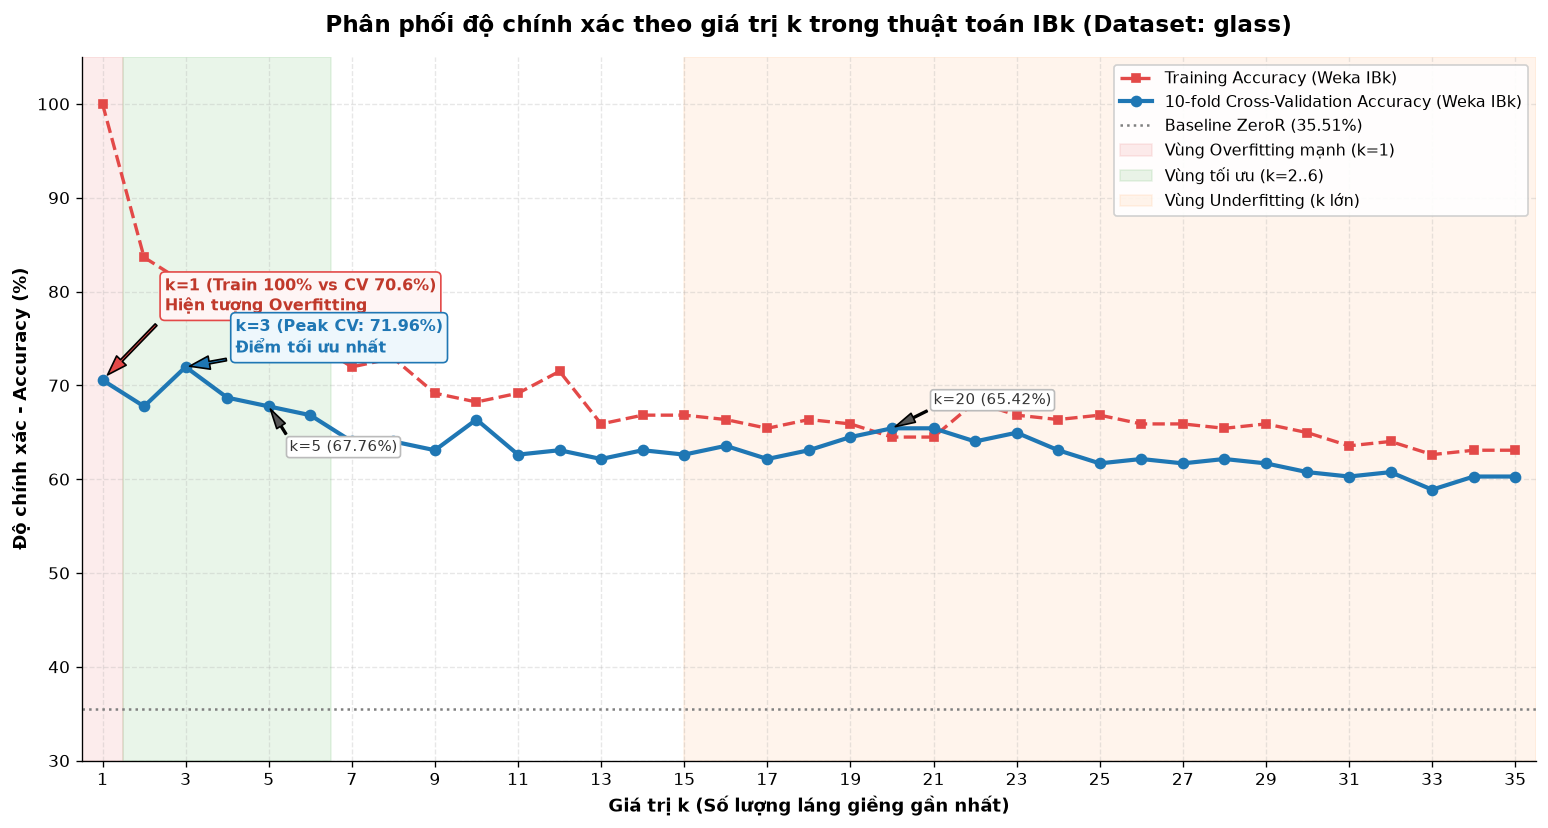

In [6]:
fig, ax = plt.subplots(figsize=(13, 7))

# Dữ liệu
x = df_weka['k']
y_cv = df_weka['cv_acc']
y_train = df_weka['train_acc']

# Vẽ 2 đường: 10-fold Cross-Validation và Training Set
ax.plot(x, y_train, marker='s', markersize=5, linewidth=2, color='#e34948', label='Training Accuracy (Weka IBk)', linestyle='--')
ax.plot(x, y_cv, marker='o', markersize=6, linewidth=2.5, color='#1f77b4', label='10-fold Cross-Validation Accuracy (Weka IBk)')

# Đường tham chiếu Baseline ZeroR
ax.axhline(acc_zeror, color='#7f7f7f', linestyle=':', linewidth=1.5, label=f'Baseline ZeroR ({acc_zeror:.2f}%)')

# Đánh dấu các vùng Overfitting, Tối ưu và Underfitting
ax.axvspan(0.5, 1.5, color='#e34948', alpha=0.10, label='Vùng Overfitting mạnh (k=1)')
ax.axvspan(1.5, 6.5, color='#2ca02c', alpha=0.10, label='Vùng tối ưu (k=2..6)')
ax.axvspan(15, 35.5, color='#ff7f0e', alpha=0.08, label='Vùng Underfitting (k lớn)')

# Annotate điểm k = 1 (Overfitting)
ax.annotate(f'k=1 (Train 100% vs CV {y_cv.iloc[0]:.1f}%)\nHiện tượng Overfitting',
            xy=(1, y_cv.iloc[0]), xytext=(2.5, 78),
            arrowprops=dict(facecolor='#e34948', shrink=0.08, width=1.5, headwidth=8),
            fontsize=9.5, fontweight='bold', color='#c0392b',
            bbox=dict(boxstyle='round,pad=0.3', facecolor='#fef5f5', edgecolor='#e34948'))

# Annotate điểm k = 3 (Tối ưu)
k_opt = int(k_toi_uu['k'])
ax.annotate(f'k={k_opt} (Peak CV: {k_toi_uu["cv_acc"]:.2f}%)\nĐiểm tối ưu nhất',
            xy=(k_opt, k_toi_uu['cv_acc']), xytext=(k_opt + 1.2, 73.5),
            arrowprops=dict(facecolor='#1f77b4', shrink=0.08, width=1.5, headwidth=8),
            fontsize=9.5, fontweight='bold', color='#1f77b4',
            bbox=dict(boxstyle='round,pad=0.3', facecolor='#eef7fc', edgecolor='#1f77b4'))

# Annotate các mốc k = 5 và k = 20
y_k5 = df_weka.loc[df_weka['k'] == 5, 'cv_acc'].values[0]
ax.annotate(f'k=5 ({y_k5:.2f}%)', xy=(5, y_k5), xytext=(5.5, 63),
            arrowprops=dict(facecolor='#555', shrink=0.08, width=1, headwidth=6),
            fontsize=9, color='#333',
            bbox=dict(boxstyle='round,pad=0.2', facecolor='white', edgecolor='#bbb'))

y_k20 = df_weka.loc[df_weka['k'] == 20, 'cv_acc'].values[0]
ax.annotate(f'k=20 ({y_k20:.2f}%)', xy=(20, y_k20), xytext=(21, 68),
            arrowprops=dict(facecolor='#555', shrink=0.08, width=1, headwidth=6),
            fontsize=9, color='#333',
            bbox=dict(boxstyle='round,pad=0.2', facecolor='white', edgecolor='#bbb'))

# Trang trí trục
ax.set_title("Phân phối độ chính xác theo giá trị k trong thuật toán IBk (Dataset: glass)", fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel("Giá trị k (Số lượng láng giềng gần nhất)", fontsize=11, fontweight='bold')
ax.set_ylabel("Độ chính xác - Accuracy (%)", fontsize=11, fontweight='bold')
ax.set_xticks(range(1, 36, 2))
ax.set_xlim(0.5, 35.5)
ax.set_ylim(30, 105)

# Bật lưới và loại bỏ đường viền thừa
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.legend(loc='upper right', frameon=True, framealpha=0.9, fontsize=9.5)

plt.tight_layout()
plt.savefig("ibk_glass_k_vs_accuracy.png", dpi=150)
plt.show()


## 7. Biểu đồ cột so sánh chi tiết các mốc $k = 1, 5, 20$ và $k$ tối ưu

Biểu đồ so sánh trực tiếp giữa **Training Accuracy** và **10-fold Cross-Validation Accuracy** tại 4 mốc tiêu biểu, giúp trực quan hóa rõ ràng sự suy giảm overfitting và hiệu năng thực tế.


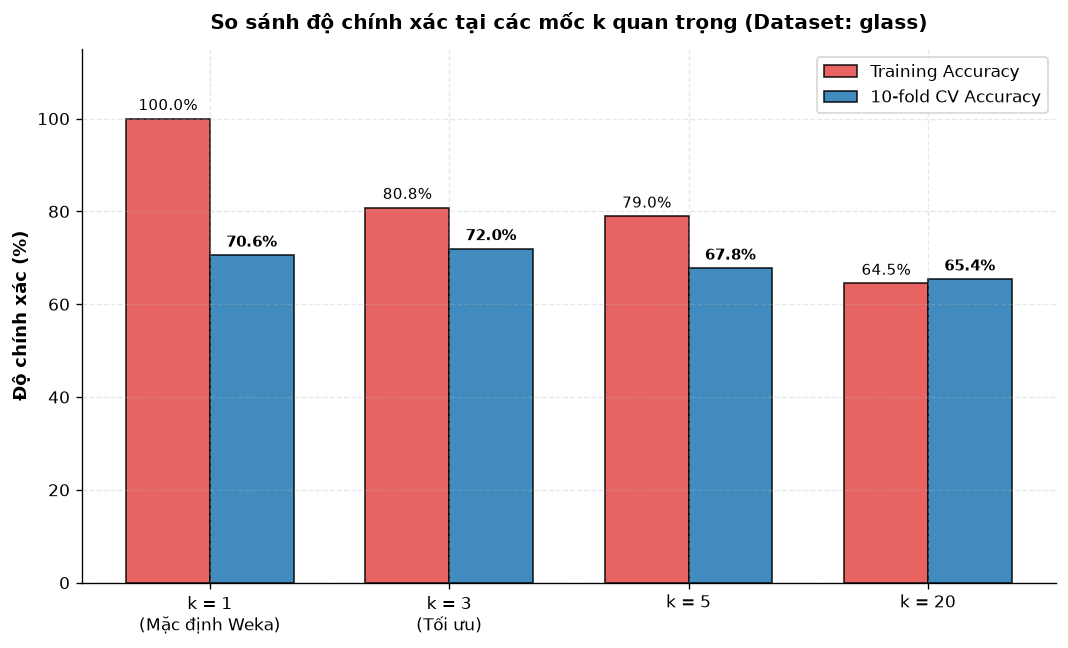

In [7]:
moc_k_ve = [1, 3, 5, 20]
nhan_moc = [f"k = {k}\n(Mặc định Weka)" if k==1 else f"k = {k}\n(Tối ưu)" if k==3 else f"k = {k}" for k in moc_k_ve]

df_sub = df_weka[df_weka['k'].isin(moc_k_ve)].sort_values('k')
train_vals = df_sub['train_acc'].values
cv_vals = df_sub['cv_acc'].values

x_idx = np.arange(len(moc_k_ve))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 5.5))
bar1 = ax.bar(x_idx - width/2, train_vals, width, label='Training Accuracy', color='#e34948', edgecolor='black', alpha=0.85)
bar2 = ax.bar(x_idx + width/2, cv_vals, width, label='10-fold CV Accuracy', color='#1f77b4', edgecolor='black', alpha=0.85)

# Ghi giá trị trên mỗi cột
ax.bar_label(bar1, fmt='%.1f%%', padding=3, fontsize=9)
ax.bar_label(bar2, fmt='%.1f%%', padding=3, fontsize=9, fontweight='bold')

ax.set_xticks(x_idx)
ax.set_xticklabels(nhan_moc, fontsize=10)
ax.set_ylim(0, 115)
ax.set_ylabel("Độ chính xác (%)", fontsize=11, fontweight='bold')
ax.set_title("So sánh độ chính xác tại các mốc k quan trọng (Dataset: glass)", fontsize=12, fontweight='bold', pad=12)
ax.legend(frameon=True, fontsize=10)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()


## 8. Nhận xét & Phân tích chuyên sâu

### 8.1. Hiện tượng Overfitting tại $k = 1$
- Khi $k = 1$, mô hình đạt **100% độ chính xác trên Training Set** (214/214 mẫu đúng). Điều này hoàn toàn tự nhiên vì với mỗi mẫu trong tập huấn luyện, láng giềng gần nhất chính là bản thân nó (khoảng cách = 0).
- Tuy nhiên, khi kiểm định chéo (**10-fold Cross-Validation**), độ chính xác giảm xuống còn **70.56%** (151/214 mẫu đúng). Sự chênh lệch gần 30% này là minh chứng rõ nét cho hiện tượng **Overfitting** (mô hình ghi nhớ quá mức nhiễu và ngoại lai trong tập huấn luyện).

### 8.2. Sự biến thiên độ chính xác khi thay đổi $k$
- **$k = 3$ đạt đỉnh tối ưu**: Độ chính xác 10-fold CV cao nhất đạt **71.96%** (154/214 mẫu đúng) tại $k = 3$. Tại điểm này, việc lấy 3 láng giềng giúp loại bỏ được nhiễu cục bộ của $k=1$ mà không làm nhòe ranh giới giữa các lớp kính.
- **Khi $k$ tăng ($k = 5 	o 20 	o 35$)**:
  - Tại $k = 5$: CV accuracy giảm xuống **67.76%** (145/214).
  - Tại $k = 20$: CV accuracy giảm xuống **65.42%** (140/214).
  - Khi $k > 25$: Độ chính xác tiếp tục giảm xuống dưới 60%.
  - **Nguyên nhân (Underfitting & Class Imbalance)**: Bộ dữ liệu `glass` có các lớp kích thước rất chênh lệch (lớp `tableware` chỉ có 9 mẫu, `containers` có 13 mẫu, trong khi `build wind non-float` có tới 76 mẫu). Khi $k$ lớn (ví dụ $k=20$), quả cầu láng giềng quá rộng sẽ bao trùm nhiều điểm của các lớp đa số, khiến các lớp thiểu số bị lấn át khi bỏ phiếu đa số.

### 8.3. Kết luận và số liệu điền form bài Lab 3:
| Dataset | IBk, $k = 1$ | IBk, $k = 5$ | IBk, $k = 20$ |
| :--- | :---: | :---: | :---: |
| **Glass** | **70.56%** (151/214) | **67.76%** (145/214) | **65.42%** (140/214) |

- **Giá trị $k$ tốt nhất trên Weka 10-fold CV**: $k = 3$ (71.96% - 154/214 mẫu đúng).
- **Khuyến nghị**: Đối với bộ dữ liệu `glass`, nên chọn giá trị $k$ nhỏ lẻ ($k = 3$ hoặc $k = 1$) và luôn chuẩn hóa thuộc tính trước khi tính khoảng cách.
